![Logo SENATI](logo_senati.png)

**SENATI | Escuela de Tecnologías de la Información**  
**Taller: Machine Learning y Deep Learning**  
*Instructor: Ing. Gunar Castro Iñigo*

---

# Sistema de estimación de pedidos de kits de robótica — caso práctico intermedio

**Contexto:** Una tienda educativa quiere anticipar pedidos semanales. El número de consultas y la inversión publicitaria pueden asociarse con más ventas; el indicador de campaña escolar toma 0 o 1.

**Objetivo:** aplicar regresión múltiple desde lectura de datos hasta una web pequeña. Aquí no se entrega el resultado completo: debes demostrar lo que aprendiste durante los cuatro proyectos.

## Paso 1. Explorar el CSV

**Variables y significado en la vida real**

- `consultas_web`: cantidad de consultas que la tienda recibe por su web en la semana (interesados).
- `inversion_publicidad_soles`: dinero gastado en publicidad esa semana, en soles.
- `campana_escolar`: 1 si esa semana hubo campaña escolar, 0 si no.
- `pedidos_kits` (**y**): kits de robótica pedidos en la semana; es lo que queremos estimar.

**¿Cuál sería el peligro de usar esta predicción sin verificarla?**

Comprar o preparar stock según una cifra que puede fallar: si la estimación es muy alta se inmoviliza dinero en kits sin vender; si es muy baja se pierden ventas. Además los datos son **simulados**, y el modelo no conoce feriados, la competencia ni cambios del mercado.

In [1]:
import pandas as pd

datos = pd.read_csv('datos.csv', encoding='utf-8-sig')
print(datos.head())
print()
print('Filas y columnas:', datos.shape)
print()
print('Valores ausentes por columna:')
print(datos.isna().sum())
print()
print('Filas duplicadas:', datos.duplicated().sum())
print()
print(datos.describe().round(2).to_string())


  semana  consultas_web  ...  campana_escolar  pedidos_kits
0   S001             31  ...                1            22
1   S002             51  ...                0            20
2   S003             27  ...                0            17
3   S004             45  ...                0            21
4   S005             40  ...                1            16

[5 rows x 5 columns]

Filas y columnas: (110, 5)

Valores ausentes por columna:
semana                        0
consultas_web                 0
inversion_publicidad_soles    0
campana_escolar               0
pedidos_kits                  0
dtype: int64

Filas duplicadas: 0

       consultas_web  inversion_publicidad_soles  campana_escolar  pedidos_kits
count         110.00                      110.00           110.00        110.00
mean           32.22                      577.73             0.51         19.36
std            18.69                      323.26             0.50          7.73
min             5.00                        

**Lectura del resultado:** el CSV no tiene valores ausentes ni filas repetidas, así que no hace falta rellenar ni eliminar datos. La primera columna es solo un identificador y no se usa como variable.

## Paso 2. Entrenar

Variables usadas: las tres columnas `X` indicadas arriba y la respuesta `y`. Reservo **80 % para entrenar y 20 % para probar** (`random_state=42` para que el sorteo sea repetible).

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

columnas = ['consultas_web', 'inversion_publicidad_soles', 'campana_escolar']
objetivo = 'pedidos_kits'
X = datos[columnas]
y = datos[objetivo]

# Separar: 80 % entrenamiento / 20 % prueba
X_entr, X_prueba, y_entr, y_prueba = train_test_split(X, y, test_size=0.2, random_state=42)
print('Filas de entrenamiento:', len(X_entr), '| Filas de prueba:', len(X_prueba))

# Entrenar el modelo
modelo = LinearRegression()
modelo.fit(X_entr, y_entr)

# Predecir sobre los datos de prueba y evaluar
prediccion = modelo.predict(X_prueba)
mae = mean_absolute_error(y_prueba, prediccion)
r2 = r2_score(y_prueba, prediccion)
print(f'MAE: {mae:.3f} kits por semana')
print(f'R2 : {r2:.3f}')


Filas de entrenamiento: 88 | Filas de prueba: 22
MAE: 2.954 kits por semana
R2 : 0.791


In [3]:
# Coeficientes del modelo
print(f'Intercepto: {modelo.intercept_:.4f}')
for nombre, coef in zip(columnas, modelo.coef_):
    print(f'  {nombre}: {coef:+.4f}')


Intercepto: 1.5385
  consultas_web: +0.3463
  inversion_publicidad_soles: +0.0067
  campana_escolar: +5.0182


### Coeficientes explicados

- **consultas_web (+0.3463)**: cada consulta web adicional se asocia con ≈ 0.35 kits más por semana, con la misma inversión y la misma campaña.
- **inversion_publicidad_soles (+0.0067)**: cada S/ 1 adicional suma ≈ 0.0067 kits; por cada S/ 100 más, ≈ 0.67 kits.
- **campana_escolar (+5.0182)**: una semana con campaña escolar trae ≈ 5.02 kits más que una sin campaña, con iguales consultas e inversión.
- **Intercepto (1.538)**: punto de partida de la ecuación (0 consultas, S/ 0 y sin campaña). Está fuera del rango de los datos (mínimo 5 consultas), por eso no representa una semana real.

### MAE y R² en las unidades del problema

**MAE = 2.95**: al predecir semanas que no vio al entrenar, el modelo se equivoca en promedio ≈ 3.0 kits por semana. Como el promedio real es ≈ 19.4 kits, el error típico es ≈ 15 % de un pedido normal.

**R² = 0.79**: el modelo explica ≈ 79 % de la variación de los pedidos; el ≈ 21 % restante depende de factores que no están en el CSV.

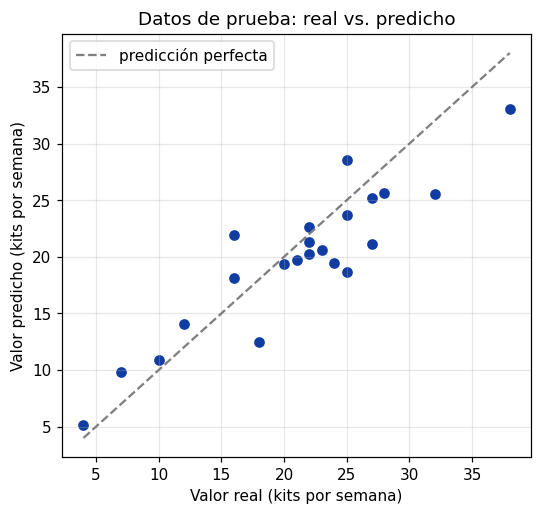

In [4]:
import matplotlib.pyplot as plt

# Valores reales vs. valores predichos en los datos de prueba
plt.figure(figsize=(5.5, 5))
plt.scatter(y_prueba, prediccion, color='#113da2')
limites = [min(y_prueba.min(), prediccion.min()), max(y_prueba.max(), prediccion.max())]
plt.plot(limites, limites, '--', color='gray', label='predicción perfecta')
plt.xlabel('Valor real (kits por semana)')
plt.ylabel('Valor predicho (kits por semana)')
plt.title('Datos de prueba: real vs. predicho')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [5]:
import json
import joblib

# Guardar los coeficientes para la aplicación Flask (modelo.json)
resumen = {
    'caso': 'Cuaderno de desarrollo',
    'objetivo': objetivo,
    'unidad_objetivo': 'kits por semana',
    'columnas': columnas,
    'intercepto': float(modelo.intercept_),
    'coeficientes': {c: float(k) for c, k in zip(columnas, modelo.coef_)},
    'metricas': {'mae': float(mae), 'r2': float(r2),
                 'filas_entrenamiento': int(len(X_entr)), 'filas_prueba': int(len(X_prueba)),
                 'filas_total': int(len(datos)), 'random_state': 42},
}
# Se muestra el contenido; el archivo oficial lo genera entrenar.py con el mismo resultado.
print(json.dumps(resumen, indent=2, ensure_ascii=False))


{
  "caso": "Cuaderno de desarrollo",
  "objetivo": "pedidos_kits",
  "unidad_objetivo": "kits por semana",
  "columnas": [
    "consultas_web",
    "inversion_publicidad_soles",
    "campana_escolar"
  ],
  "intercepto": 1.5384729585592574,
  "coeficientes": {
    "consultas_web": 0.3463033562740661,
    "inversion_publicidad_soles": 0.006699109182241925,
    "campana_escolar": 5.018213367145449
  },
  "metricas": {
    "mae": 2.954102420565232,
    "r2": 0.7910735136647091,
    "filas_entrenamiento": 88,
    "filas_prueba": 22,
    "filas_total": 110,
    "random_state": 42
  }
}


## Paso 3. Aplicación web

La aplicación está en `app.py`, `templates/index.html` y `static/estilos.css` (**solo Python, Flask, HTML y CSS; sin JavaScript**). Tiene título realista, 3 campos con unidades, botón «Calcular», resultado y una advertencia de estimación. Valida rangos en Python y lee los coeficientes de `modelo.json`.

Para ejecutarla:

```
pip install -r requirements.txt
python entrenar.py   # genera modelo.json y modelo.pkl
python app.py       # abre http://127.0.0.1:5000
```

## Paso 4. Pruebas obligatorias

In [6]:
import json

# Se usa el modelo.json que guardó entrenar.py, igual que la aplicación web.
with open('modelo.json', encoding='utf-8') as f:
    m = json.load(f)

def predecir(**valores):
    return m['intercepto'] + sum(m['coeficientes'][c] * valores[c] for c in m['columnas'])

print('Semana con 20 consultas, S/ 200 y sin campaña:', round(predecir(**{'consultas_web': 20, 'inversion_publicidad_soles': 200, 'campana_escolar': 0}), 2))
print('Semana con 55 consultas, S/ 800 y con campaña:', round(predecir(**{'consultas_web': 55, 'inversion_publicidad_soles': 800, 'campana_escolar': 1}), 2))

Semana con 20 consultas, S/ 200 y sin campaña: 9.8
Semana con 55 consultas, S/ 800 y con campaña: 30.96


- **Semana con 20 consultas, S/ 200 y sin campaña** → 9.8 kits (≈ 10).
- **Semana con 55 consultas, S/ 800 y con campaña** → 31.0 kits (≈ 31).

**¿Tienen sentido?** Sí: la segunda semana tiene más consultas, más publicidad y campaña escolar, y el sistema devuelve bastantes más pedidos que la primera. El orden y el tamaño de la diferencia coinciden con lo que muestran los coeficientes.

**¿Cuándo podría fallar?** Con valores fuera de los rangos entrenados (5–70 consultas, S/ 0–1100), en semanas atípicas (feriados, quiebre de stock, un competidor con oferta) o si la relación real no es lineal (por ejemplo, si la publicidad rinde cada vez menos).

## Evidencias y conclusiones

Archivos entregados: este cuaderno ejecutado, `datos.csv`, `entrenar.py`, `modelo.json` (y `modelo.pkl`), la aplicación Flask, `pruebas.py` con su resultado, la carpeta `capturas/` y `EXPLICACION_Y_CONCLUSIONES.md`.

**Límites del modelo**

- **Datos simulados y pocos:** solo 110 semanas, y la prueba usa apenas 22; las métricas cambiarían con otra separación.
- **Error que no desaparece:** con R² = 0.79, ≈ 21 % de la variación queda sin explicar; en una semana concreta el error puede superar los 3.0 kits promedio.
- **Supone una relación lineal y constante:** cada consulta o cada sol de publicidad aporta lo mismo siempre; en la realidad la publicidad suele rendir cada vez menos.
- **Solo 3 variables:** no considera precio, stock, feriados, competencia ni el calendario escolar real.
- **No extrapola:** fuera de 5–70 consultas y S/ 0–1100 la aplicación rechaza el dato porque el modelo no fue entrenado ahí.
- **Uso recomendado:** apoyo para planificar compras; la decisión final debe verificarse con el criterio del encargado de la tienda.